# The Euler system and its Riemann problem

The Euler equations carry 3 unknowns, so one discontinuity now resolves into 3 waves.

* **Part I.** Is the system hyperbolic? Build the flux Jacobian, get its eigenvalues and eigenvectors, and check the factorisation.

* **Part II.** Riemann problem for Sod: pressure function (its single root), and the wave fan.

* **Part III.** Complete solution: sample it at any $x/t$ and plot the profiles.

The equations are:

$$\frac{\partial \mathbf{U}}{\partial t} +
\frac{\partial \mathbf{F}(\mathbf{U})}{\partial x} = 0,
\qquad
\mathbf{U} = \begin{bmatrix} \rho \\ \rho u \\ E \end{bmatrix},
\qquad
\mathbf{F}(\mathbf{U}) = \begin{bmatrix} \rho u \\ \rho u^2 + p \\ u(E + p)
\end{bmatrix}$$

**References**: E. F. Toro, *Riemann Solvers and Numerical Methods for Fluid Dynamics*, 2nd ed., Chapters 3 and 4. M. Zingale, *Introduction to Computational Astrophysical Hydrodynamics*, Chapter 7.

Notation follows the lectures: $\rho$ is the density, $u$ the velocity, $p$ the pressure and $c = \sqrt{\gamma p/\rho}$ the sound speed, and the three waves are labelled $(-)$, $(\circ)$ and $(+)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Part I. Hyperbolicity

### 1. The state and the EOS:

In [2]:
def primitive_to_conserved(rho, u, p, gamma = 1.4):
    """
    Function to build U = (rho, rho*u, E) from the primitive variables.
    """

    # Specific internal energy from the gamma-law EOS
    e = p/((gamma - 1.)*rho)

    # Total energy per unit volume
    E = rho*(0.5*u**2 + e)

    return np.array([rho, rho*u, E], dtype = np.float64)

In [3]:
def sound_speed(rho, p, gamma = 1.4):
    """
    Function to compute the speed of sound for an ideal gas.
    """

    return np.sqrt(gamma*p/rho)

### 2. The flux Jacobian:

We use the form written in terms of $u$ and $c$ (Toro, Eq. 3.8, and Zingale, Eq. 7.14):

$$\mathbf{A}(\mathbf{U}) = \begin{bmatrix}
0 & 1 & 0\\
\frac{1}{2}(\gamma - 3)u^{2} & (3 - \gamma)u & \gamma - 1\\
\frac{1}{2}(\gamma - 2)u^{3} - \frac{c^{2}u}{\gamma - 1} &
\frac{3 - 2\gamma}{2}u^{2} + \frac{c^{2}}{\gamma - 1} & \gamma u
\end{bmatrix}$$

In [4]:
def jacobian(rho, u, p, gamma):
    """
    The flux Jacobian A = dF/dU of the 1D Euler equations.
    inputs: rho, u, p, gamma
    Output: A
    """

    # Sound speed
    c = sound_speed(rho, p, gamma)

    # Empty matrix, use high precision
    A = np.zeros((3, 3), dtype = np.float64)

    # First row
    A[0, 1] = 1.

    # Second row
    A[1, 0] = 0.5*(gamma - 3.)*u**2
    A[1, 1] = (3. - gamma)*u
    A[1, 2] = gamma - 1.

    # Third row
    A[2, 0] = 0.5*(gamma - 2.)*u**3 - c**2*u/(gamma - 1.)
    A[2, 1] = (3. - 2.*gamma)/2.*u**2 + c**2/(gamma - 1.)
    A[2, 2] = gamma*u

    return A

### 3. A test state:

Any state will do. We take the left state of the Sod problem, but moving, so that
the three wave speeds are distinct and none of them is zero.

In [5]:
# Ratio of specific heats
gamma = 1.4

# Test state
rho, u, p = 1.0, 0.5, 1.0

# Sound speed and Jacobian for this state
c = sound_speed(rho, p, gamma)
A = jacobian(rho, u, p, gamma)

In [6]:
print("c =", round(c,3))
print("\n")
print("A =")
print(A)

c = 1.183


A =
[[ 0.      1.      0.    ]
 [-0.2     0.8     0.4   ]
 [-1.7875  3.525   0.7   ]]


### 4. The homogeneity property:

For an ideal gas, the flux is the Jacobian acting on the state, $\mathbf{F} = \mathbf{A}\mathbf{U}$ (Toro, Eq. 3.11).

This is a quick check that the matrix above was typed in correctly.

In [7]:
# Conserved vector and flux for the test state

U = primitive_to_conserved(rho, u, p, gamma)

F = np.array([rho*u, rho*u**2 + p, u*(U[2] + p)], dtype = np.float64)


In [8]:
print("F       =", F)
print("A . U   =", A @ U)

F       = [0.5    1.25   1.8125]
A . U   = [0.5    1.25   1.8125]


### 5. Eigenvalues:

Remember:

$\lambda^{(-)} = u - c$,

$\lambda^{(\circ)} = u$,

$\lambda^{(+)} = u + c$.

We let numpy find them and compare.

In [9]:
# Numerical eigenvalues and right eigenvectors.
# The columns of R are the eigenvectors, one per eigenvalue.
lam, R = np.linalg.eig(A)

# Sort them into the order u-a, u, u+a
order = np.argsort(lam)
lam = lam[order]
R = R[:, order]

# The expected values
lam_exact = np.array([u - c, u, u + c])

print("numerical :", lam)
print("expected  :", lam_exact)

numerical : [-0.68321596  0.5         1.68321596]
expected  : [-0.68321596  0.5         1.68321596]


### 6. Factorisation:

If the eigenvalues and the eigenvectors are both right, then

$$\mathbf{A} = \mathbf{R}\,\boldsymbol{\Lambda}\,\mathbf{R}^{-1}$$

$$\boldsymbol{\Lambda} = {\rm diag}\left(u - c,\ u,\ u + c\right)$$

In [10]:
# Diagonal matrix of eigenvalues
Lam = np.diag(lam)

# Rebuild A from its eigen-decomposition
A_rebuilt = R @ Lam @ np.linalg.inv(R)

# Safe checks
print("max |A - R Lambda R^-1| =", np.max(np.abs(A - A_rebuilt)))

# The left eigenvectors are the rows of the inverse
L = np.linalg.inv(R)
print("max |L R - I|           =", np.max(np.abs(L @ R - np.eye(3))))

max |A - R Lambda R^-1| = 8.881784197001252e-16
max |L R - I|           = 1.8370117693683747e-16


### 7. The eigenvectors in primitive variables:

The conserved eigenvectors are hard to read.

In the primitive variables $\mathbf{q} = (\rho, u, p)$ the matrix and its eigenvectors are much simpler,

$$\mathbf{A}(\mathbf{q}) = \begin{bmatrix}
u & \rho & 0\\ 0 & u & 1/\rho\\ 0 & \gamma p & u \end{bmatrix}$$


$$\mathbf{r}^{(-)} = \begin{bmatrix} 1 \\ -c/\rho \\ c^{2}\end{bmatrix}$$

$$\mathbf{r}^{(\circ)} = \begin{bmatrix} 1 \\ 0 \\ 0\end{bmatrix}$$

$$\mathbf{r}^{(+)} = \begin{bmatrix} 1 \\ c/\rho \\ c^{2}\end{bmatrix}$$

The middle state indicates that only the density jumps across the contact.

In [11]:
# The primitive-variable matrix
Aq = np.array([[u,  rho, 0.   ],
               [0., u,   1./rho],
               [0., gamma*p, u]], dtype = np.float64)

# Its eigenvalues, sorted
lam_q = np.sort(np.linalg.eigvals(Aq).real)

print("eigenvalues of A(q) :", lam_q)

# The theoretical right eigenvectors (columns)
Rq = np.array([[1.,      1., 1.    ],
               [-c/rho,  0., c/rho ],
               [c**2,    0., c**2  ]], dtype = np.float64)

# Check each one: A r = lambda r
for k, lk in enumerate([u - c, u, u + c]):
    print("wave %d:  lambda = %+8.5f" % (k + 1, lk))

eigenvalues of A(q) : [-0.68321596  0.5         1.68321596]
wave 1:  lambda = -0.68322
wave 2:  lambda = +0.50000
wave 3:  lambda = +1.68322


### 8. Characteristic families (3):

Each eigenvalue defines a direction $dx/dt = \lambda$ in the $x$-$t$ plane.

For a single constant state the characteristics are straight and parallel: this is the picture before any wave interaction.

In [12]:
# Time levels and a few starting points for each family
t = np.linspace(0., 1., 50)
x_start = np.linspace(0., 1., 9)

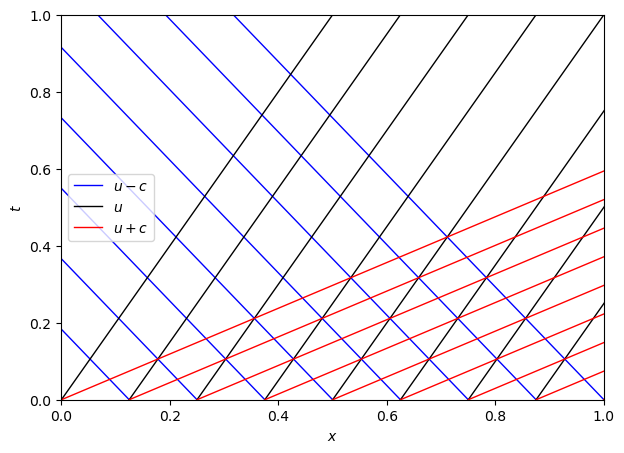

In [13]:
plt.figure(figsize = (7,5))

# One family per eigenvalue
speeds = [u - c, u, u + c]
colours = ["blue", "black", "red"]
labels = [r"$u - c$", r"$u$", r"$u + c$"]

for sp, col, lab in zip(speeds, colours, labels):
    for k, xk in enumerate(x_start):
        plt.plot(xk + sp*t, t, color = col, lw = 1., label = lab if k == 0 else None)

plt.xlabel(r"$x$")
plt.ylabel(r"$t$")
plt.xlim(0., 1.)
plt.ylim(0., 1.)

plt.legend()
plt.show()

## Part II. The Riemann problem

Two constant states separated by a discontinuity.

- The middle wave is always a contact discontinuity.

- The outer two are each either a shock or a rarefaction.

Pressure and velocity are constant across the contact, so the only unknowns are $p_\star$, $u_\star$ and the 2 densities.

Each outer wave gives one relation between $u_\star$ and $p_\star$, and eliminating $u_\star$ leaves a single equation (Toro, Eq. 4.5):

$$f(p) = f_L(p, \mathbf{q}_L) + f_R(p, \mathbf{q}_R) + \Delta u = 0$$

$$\Delta u = u_R - u_L$$

### 1. Sod's test problem (Toro's Test 1)

In [14]:
# Sod's test problem (Toro's Test 1)
rhoL, uL, pL = 1.0,   0.0, 1.0
rhoR, uR, pR = 0.125, 0.0, 0.1

# Position of the diaphragm and the time at which we look at the solution
x0 = 0.5
tend = 0.25

# Sound speeds on each side
cL = sound_speed(rhoL, pL, gamma)
cR = sound_speed(rhoR, pR, gamma)

print("c_L =", round(cL,4))
print("c_R =", round(cR,4))

c_L = 1.1832
c_R = 1.0583


### 2. The pressure function:

$$f_K(p) = \begin{cases}
(p - p_K)\left[\dfrac{A_K}{p + B_K}\right]^{1/2} & p > p_K \quad {\rm (shock)}\\[12pt]
\dfrac{2c_K}{\gamma - 1}\left[\left(\dfrac{p}{p_K}\right)^{(\gamma - 1)/2\gamma}
- 1\right] & p \leq p_K \quad {\rm (rarefaction)}
\end{cases}
\qquad
\begin{aligned}
A_K &= \frac{2}{(\gamma + 1)\rho_K}\\
B_K &= \frac{\gamma - 1}{\gamma + 1}p_K
\end{aligned}$$

In [15]:
def f_K(p, rhoK, uK, pK, gamma = 1.4):
    """
    One side of the pressure function, for the left or the right state.
    """

    # Sound speed of the data state
    cK = sound_speed(rhoK, pK, gamma)

    if p > pK:
        # Shock branch
        AK = 2./((gamma + 1.)*rhoK)
        BK = (gamma - 1.)/(gamma + 1.)*pK
        return (p - pK)*np.sqrt(AK/(p + BK))

    else:
        # Rarefaction branch
        return 2.*cK/(gamma - 1.)*((p/pK)**((gamma - 1.)/(2.*gamma)) - 1.)


def f_total(p, gamma = 1.4):
    """
    Full pressure function f(p) = f_L + f_R + du.
    """

    return f_K(p, rhoL, uL, pL, gamma) + f_K(p, rhoR, uR, pR, gamma) + (uR - uL)

### 3. Is there one root?

$f$ is monotone increasing and concave down, so it crosses zero at most once. 

We scan a range of pressures and look.

In [16]:
# A range of pressures that brackets both data pressures
ps = np.linspace(0.01, 1.5, 400)
fs = np.array([f_total(pk, gamma) for pk in ps])

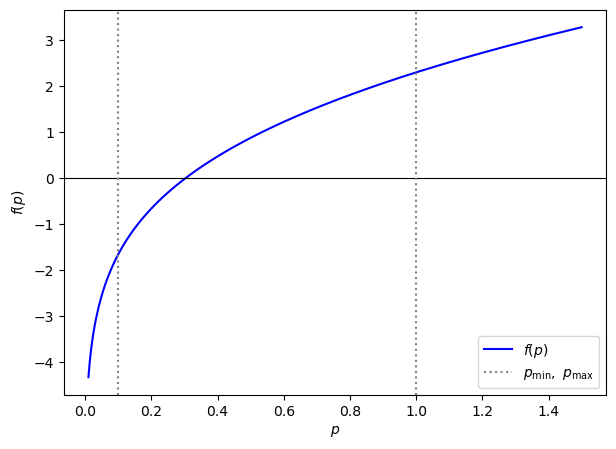

In [17]:
plt.figure(figsize = (7,5))

plt.plot(ps, fs, color = "blue", label = r"$f(p)$")
plt.axhline(0., color = "black", lw = 0.8)

# The two data pressures separate the three intervals
plt.axvline(pR, color = "grey", linestyle = ":", label = r"$p_{\rm min},\ p_{\rm max}$")
plt.axvline(pL, color = "grey", linestyle = ":")

plt.xlabel(r"$p$")
plt.ylabel(r"$f(p)$")
plt.legend()
plt.show()

In [18]:
# The signs at the two data pressures tell us the wave pattern
print("f(p_min) =", f_total(min(pL, pR), gamma))
print("f(p_max) =", f_total(max(pL, pR), gamma))

f(p_min) = -1.6583619228710595
f(p_max) = 2.304663838792128


Notice $f(p_{\rm min}) < 0$ and $f(p_{\rm max}) > 0$, so the root lies between the two data pressures, so one outer wave is a shock and the other is a rarefaction.

### 4. Finding the root:

Using the bisection method is enough. We can also use Newton's method, which needs the derivative.

In [19]:
def bisect(fun, pa, pb, tol = 1.e-12, itmax = 100):

    fa = fun(pa)

    for it in range(itmax):

        # Midpoint and its function value
        pm = 0.5*(pa + pb)
        fm = fun(pm)

        # Keep the half that still brackets the root
        if fa*fm <= 0.:
            pb = pm
        else:
            pa, fa = pm, fm

        # Stop when the bracket is small enough
        if abs(pb - pa) < tol:
            break

    return 0.5*(pa + pb), it + 1

In [20]:
# Solve for the star pressure
pstar, nit = bisect(lambda pk: f_total(pk, gamma), min(pL, pR), max(pL, pR))

# The star velocity follows from the mean of the two relations
ustar = 0.5*(uL + uR) + 0.5*(f_K(pstar, rhoR, uR, pR, gamma) - f_K(pstar, rhoL, uL, pL, gamma))

print("iterations =", nit)
print("p* =", pstar)
print("u* =", ustar)

iterations = 40
p* = 0.3031301780503327
u* = 0.9274526200488297


### 5. Other Variables of the Star State:

The left wave is a rarefaction ($p_\star < p_L$), so the density follows from the isentropic law.

The right wave is a shock ($p_\star > p_R$), so it follows from the Rankine-Hugoniot conditions.

In [21]:
# Left: rarefaction, isentropic
rho_starL = rhoL*(pstar/pL)**(1./gamma)
c_starL = cL*(pstar/pL)**((gamma - 1.)/(2.*gamma))

# Right: shock, Rankine-Hugoniot
ratio = pstar/pR
rho_starR = rhoR*(ratio*(gamma + 1.) + (gamma - 1.))/((gamma + 1.) + ratio*(gamma - 1.))

print("rho*L =", rho_starL)
print("rho*R =", rho_starR)

rho*L = 0.42631942817817964
rho*R = 0.2655737117051386


The rarefaction branch comes from the invariant $u + 2c/(\gamma - 1)$, which is constant across the left wave.

The shock branch comes from the jump conditions, which must give the same mass flux on both sides of the right wave.

In [22]:
# Rarefaction test: the invariant must take the same value in L and in L*
inv_L = uL + 2.*cL/(gamma - 1.)
inv_starL = ustar + 2.*c_starL/(gamma - 1.)

print("u + 2c/(gamma-1):   L = %.8f   L* = %.8f   difference = %.2e" % (inv_L, inv_starL, abs(inv_L - inv_starL)))

u + 2c/(gamma-1):   L = 5.91607978   L* = 5.91607978   difference = 8.58e-13


In [23]:
# Shock: mass flux seen from the shock frame, W_s = rho*(u - S), on both sides
S_shock_test = uR + cR*np.sqrt((gamma + 1.)/(2.*gamma)*pstar/pR + (gamma - 1.)/(2.*gamma))

Ws_R = rhoR*(uR - S_shock_test)
Ws_starR = rho_starR*(ustar - S_shock_test)

print("mass flux:          R = %.8f   R* = %.8f   difference = %.2e" % (Ws_R, Ws_starR, abs(Ws_R - Ws_starR)))

mass flux:          R = -0.21901947   R* = -0.21901947   difference = 2.28e-13


### 6. The 3 wave speeds:

A shock travels at a single speed. 

A rarefaction has a head and a tail, and it spreads.

The contact simply moves with the fluid.

In [24]:
# Left rarefaction: head and tail
S_head = uL - cL
S_tail = ustar - c_starL

# Contact
S_contact = ustar

# Right shock
S_shock = uR + cR*np.sqrt((gamma + 1.)/(2.*gamma)*pstar/pR + (gamma - 1.)/(2.*gamma))

print("rarefaction head  = ", S_head)
print("rarefaction tail  = ", S_tail)
print("contact           = ", S_contact)
print("shock             = ", S_shock)

rarefaction head  =  -1.1832159566199232
rarefaction tail  =  -0.07027281256115592
contact           =  0.9274526200488297
shock             =  1.7521557320293175


### 7. Wave fan:

Every wave is a straight line through the origin of the $x$-$t$ plane.

The solution depends on $x$ and $t$ only through $\xi = (x - x_0)/t$.

In [25]:
# Time axis
t = np.linspace(0., tend, 50)

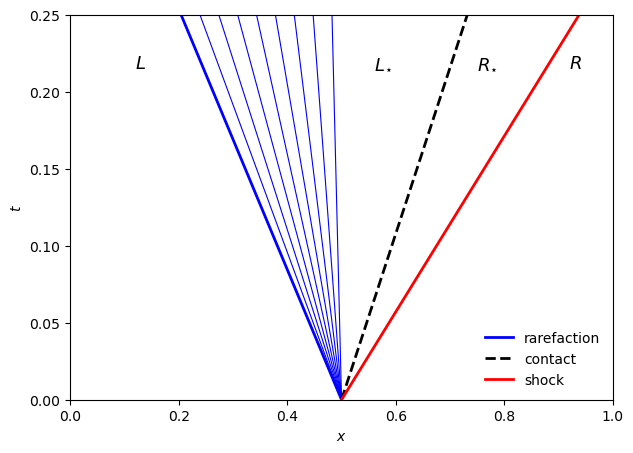

In [26]:
plt.figure(figsize = (7,5))

# Rarefaction fan
for sp in np.linspace(S_head, S_tail, 9):
    plt.plot(x0 + sp*t, t, color = "blue", lw = 0.8)

# 3 waves
plt.plot(x0 + S_head*t, t, color = "blue", lw = 2., label = "rarefaction")
plt.plot(x0 + S_contact*t, t, color = "black", linestyle = "--", lw = 2., label = "contact")
plt.plot(x0 + S_shock*t, t, color = "red", lw = 2., label = "shock")

# 4 regions
plt.text(0.12, 0.215, r"$L$", fontsize = 13)
plt.text(0.56, 0.215, r"$L_{\star}$", fontsize = 13)
plt.text(0.75, 0.215, r"$R_{\star}$", fontsize = 13)
plt.text(0.92, 0.215, r"$R$", fontsize = 13)

plt.xlabel(r"$x$")
plt.ylabel(r"$t$")
plt.xlim(0., 1.)
plt.ylim(0., tend)

plt.legend(frameon = False, loc = "lower right")
plt.show()

## Part III. Complete solution

The solution is self-similar: it depends on $x$ and $t$ only through $\xi = (x - x_0)/t$. 

Thus, one function can return the state anywhere, once it knows the star state and the wave speeds. Inside the rarefaction fan we use:

$$\frac{x}{t} = u - c$$

together with the invariant, which gives $u$ and $c$ directly.

For the Sod pattern, a left rarefaction and a right shock, the rule is the one on slide 24 of Lecture 20: we compare $\xi$ with the wave speeds and read off the state,

$$\mathbf{q}(\xi) = \begin{cases}
\mathbf{q}_L & \xi < \lambda_{\rm head}\\[3pt]
\mathbf{q}_{\rm fan}(\xi) & \lambda_{\rm head} \leq \xi \leq \lambda_{\rm tail}\\[3pt]
\mathbf{q}_{\star,L} & \lambda_{\rm tail} < \xi < u_{\star}\\[3pt]
\mathbf{q}_{\star,R} & u_{\star} \leq \xi < S\\[3pt]
\mathbf{q}_R & \xi \geq S
\end{cases}
\qquad\qquad
\begin{aligned}
\lambda_{\rm head} &= u_L - c_L\\[3pt]
\lambda_{\rm tail} &= u_{\star} - c_{\star,L}\\[3pt]
S &= u_R + c_R\sqrt{\frac{\gamma + 1}{2\gamma}\frac{p_{\star}}{p_R} + \frac{\gamma - 1}{2\gamma}}
\end{aligned}$$

with $\xi = 0$ giving the state on the interface itself.

### 1. Sampling:

In [27]:
def sample(xi, gamma):
    """
    Exact Sod solution at xi = (x - x0)/t.
    Returns (rho, u, p).
    """

    if xi < ustar:
        # Left of the contact
        if xi < S_head:
            # Still in the undisturbed left state
            return rhoL, uL, pL

        elif xi > S_tail:
            # Between the tail of the fan and the contact
            return rho_starL, ustar, pstar

        else:
            # Inside the rarefaction fan
            u_fan = 2./(gamma + 1.)*(cL + (gamma - 1.)/2.*uL + xi)
            c_fan = u_fan - xi
            rho_fan = rhoL*(c_fan/cL)**(2./(gamma - 1.))
            p_fan = pL*(c_fan/cL)**(2.*gamma/(gamma - 1.))
            return rho_fan, u_fan, p_fan

    else:
        # Right of the contact
        if xi > S_shock:
            # Still in the undisturbed right state
            return rhoR, uR, pR

        else:
            # Between the contact and the shock
            return rho_starR, ustar, pstar

In [28]:
# Check: state on the interface itself, xi = 0

print("state at xi = 0:  rho = %.6f   u = %.6f   p = %.6f" % sample(0., gamma))

state at xi = 0:  rho = 0.426319   u = 0.927453   p = 0.303130


### 2. Profiles:

We evaluate the solution on a fine grid of $x$ at a fixed time and plot all 4 variables. 

In [29]:
# Grid
x = np.linspace(0., 1., 1000)

# Sampling
q = np.array([sample((xk - x0)/tend, gamma) for xk in x])

rho, u_x, p_x = q[:, 0], q[:, 1], q[:, 2]

# Specific internal energy, from the gamma-law EOS
e_x = p_x/((gamma - 1.)*rho)

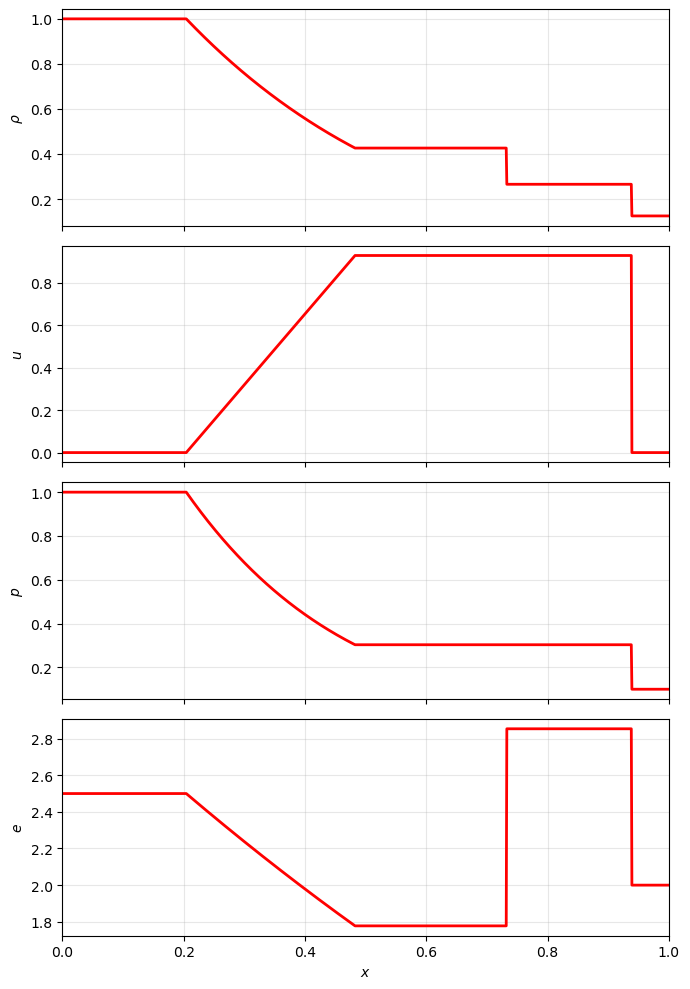

In [30]:
fig, ax = plt.subplots(4, 1, figsize = (7,10), sharex = True)

for axis, var, lab in zip(ax, [rho, u_x, p_x, e_x], [r"$\rho$", r"$u$", r"$p$", r"$e$"]):
    axis.plot(x, var, color = "red", lw = 2.)
    axis.set_ylabel(lab)
    axis.grid(alpha = 0.3)

ax[3].set_xlabel(r"$x$")
plt.xlim(0., 1.)
plt.tight_layout()
plt.show()

### Observations:

Left to right:

- the rarefaction fan spreads between its head and its tail,

- the contact is the jump in density alone, and 

- the shock is the jump in all 3 variables.

- Pressure and velocity are flat across the contact due to: $\mathbf{r}^{(\circ)} = (1, 0, 0)^{T}$.